# 03: Demand Forecasting (Phase 3)

This notebook reads the artefacts written by `python main.py forecast` (`src/forecasting.py`). Set `RETRAIN = True` to rerun the full pipeline (about 10 minutes). The full narrative is in `reports/phase3_forecasting_report.md`.

The last section reloads the saved model and shows that it reproduces the CFLP forecast.

In [1]:
import sys, os, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, pandas as pd, joblib
from IPython.display import Image, display
pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.max_colwidth', 70)
RETRAIN = False
if RETRAIN:
    import main; main.main(['forecast'])
OUT = ROOT / 'data/outputs'
ev = pd.read_csv(OUT / 'forecast_evaluation.csv')
sel = pd.read_csv(OUT / 'selected_forecast_model.csv')
cflp = pd.read_csv(OUT / 'cflp_zone_demand_forecast.csv')
imp = pd.read_csv(OUT / 'feature_importance.csv')

## 1. Stable regime: pre-break test (zone-week, one-step)

In [2]:
def wape_table(eval_set, mode='one_step', handling='none', gran='W', level='zone_period'):
    x = ev[(ev.granularity==gran)&(ev.eval_set==eval_set)&(ev['mode'].isin([mode,'reference']))&(ev.level==level)&(ev.tier=='all')&(ev.network!='ALL')]
    x = x[(x.handling==handling)|(x.handling=='reference')]
    return x.pivot_table(index=['target','network'], columns='model', values='WAPE').round(3)
wape_table('pre_break_test')

model               historical_average  moving_average  oracle_window_mean  random_forest  xgboost
target network                                                                                    
orders CONUS                     0.726           0.736               0.684          0.748    0.743
       Puerto Rico               0.167           0.175               0.162          0.172    0.185
units  CONUS                     0.830           0.838               0.771          0.852    0.846
       Puerto Rico               0.188           0.191               0.173          0.193    0.174

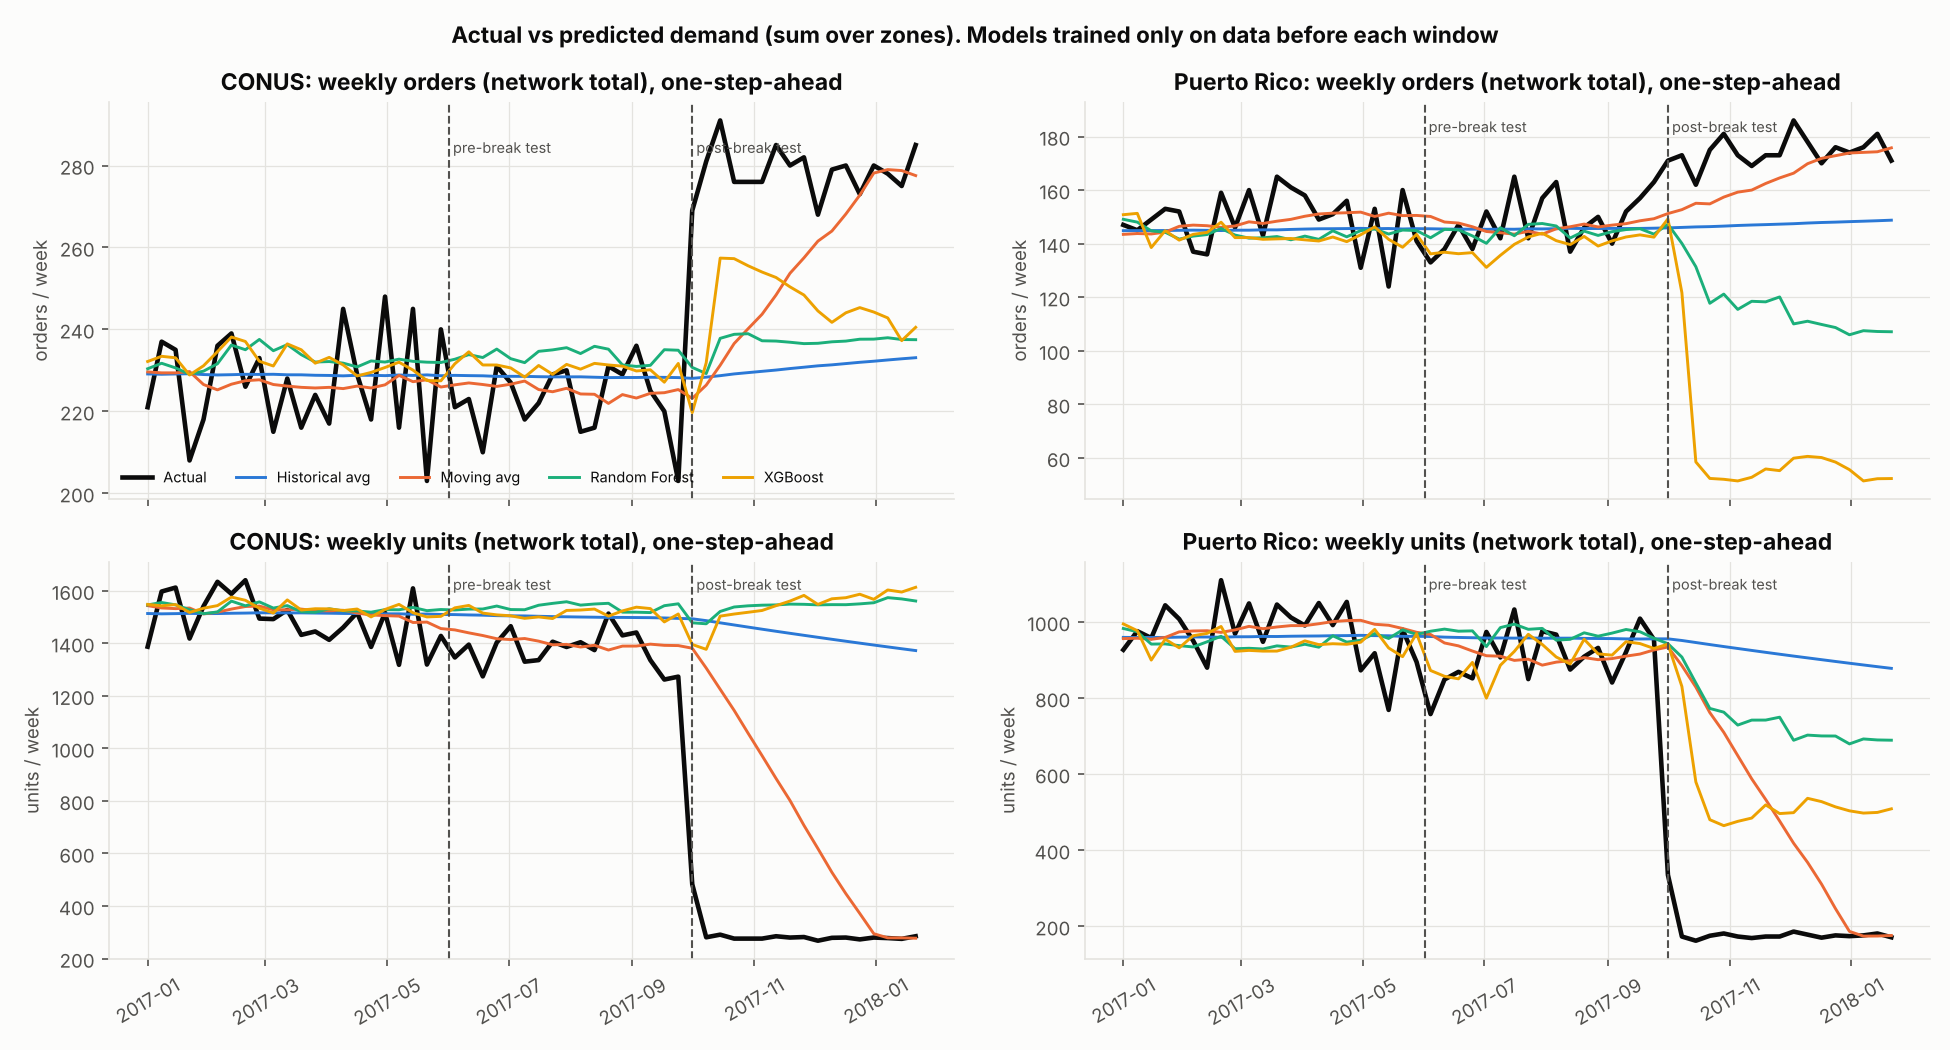

In [3]:
display(Image('reports/figures/phase3_actual_vs_predicted_network.png'))

## 2. After the October 2017 break

In [4]:
display(wape_table('post_break_test')); display(wape_table('post_break_test', mode='horizon'))

model               historical_average  moving_average  oracle_window_mean  random_forest  xgboost
target network                                                                                    
orders CONUS                     0.672           0.683               0.638          0.700    0.744
       Puerto Rico               1.587           0.753               0.159          0.941    0.967
units  CONUS                     3.991           1.894               0.661          4.354    4.350
       Puerto Rico               5.135           2.231               0.241          3.167    2.146

model               historical_average  moving_average  oracle_window_mean  random_forest  xgboost
target network                                                                                    
orders CONUS                     0.673           0.685               0.638          0.676    0.677
       Puerto Rico               1.670           1.693               0.159          1.674    1.650
units  CONUS                     4.200           3.870               0.661          4.164    4.219
       Puerto Rico               5.410           5.295               0.241          5.440    5.373

In [5]:
x = ev[(ev.granularity=='W')&(ev.eval_set=='post_break_adapted')&(ev.level=='zone_period')&(ev.tier=='all')&(ev.network!='ALL')]
x.pivot_table(index=['target','network'], columns=['model','handling'], values='WAPE').round(3)

model              historical_average              moving_average              oracle_window_mean post_break_average random_forest              share_x_recent_level xgboost             
handling                         none recalibrated           none recalibrated          reference       regime_reset          none recalibrated         regime_reset    none recalibrated
target network                                                                                                                                                                           
orders CONUS                    0.677        0.685          0.688        0.714              0.631              0.724         0.693        0.693                0.684   0.714        0.715
       Puerto Rico              1.675        1.788          1.278        1.309              0.085              0.273         1.131        1.169                1.786   1.048        1.105
units  CONUS                    4.291        0.727          2.931        0.712              0.631              0.852         4.395        0.736                0.732   4.341        0.756
       Puerto Rico              5.626        2.011          4.010        1.729              0.085              0.483         4.015        1.184                2.026   1.777        1.014

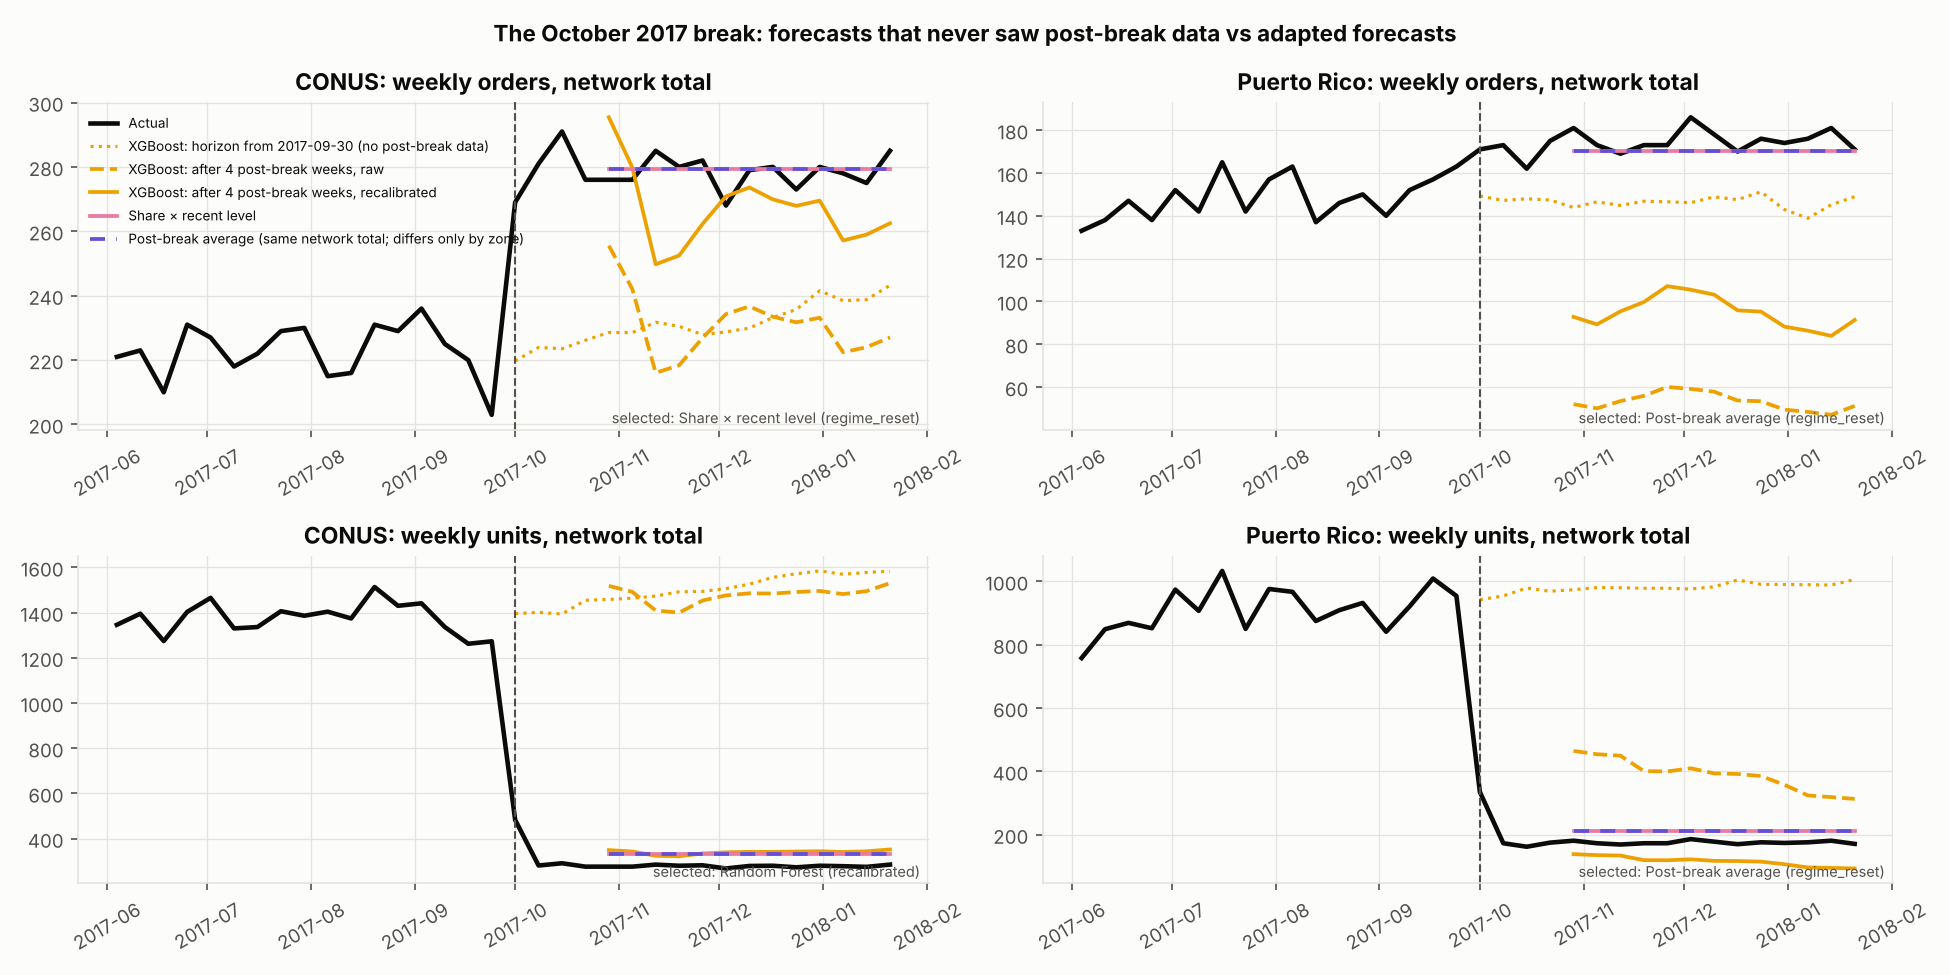

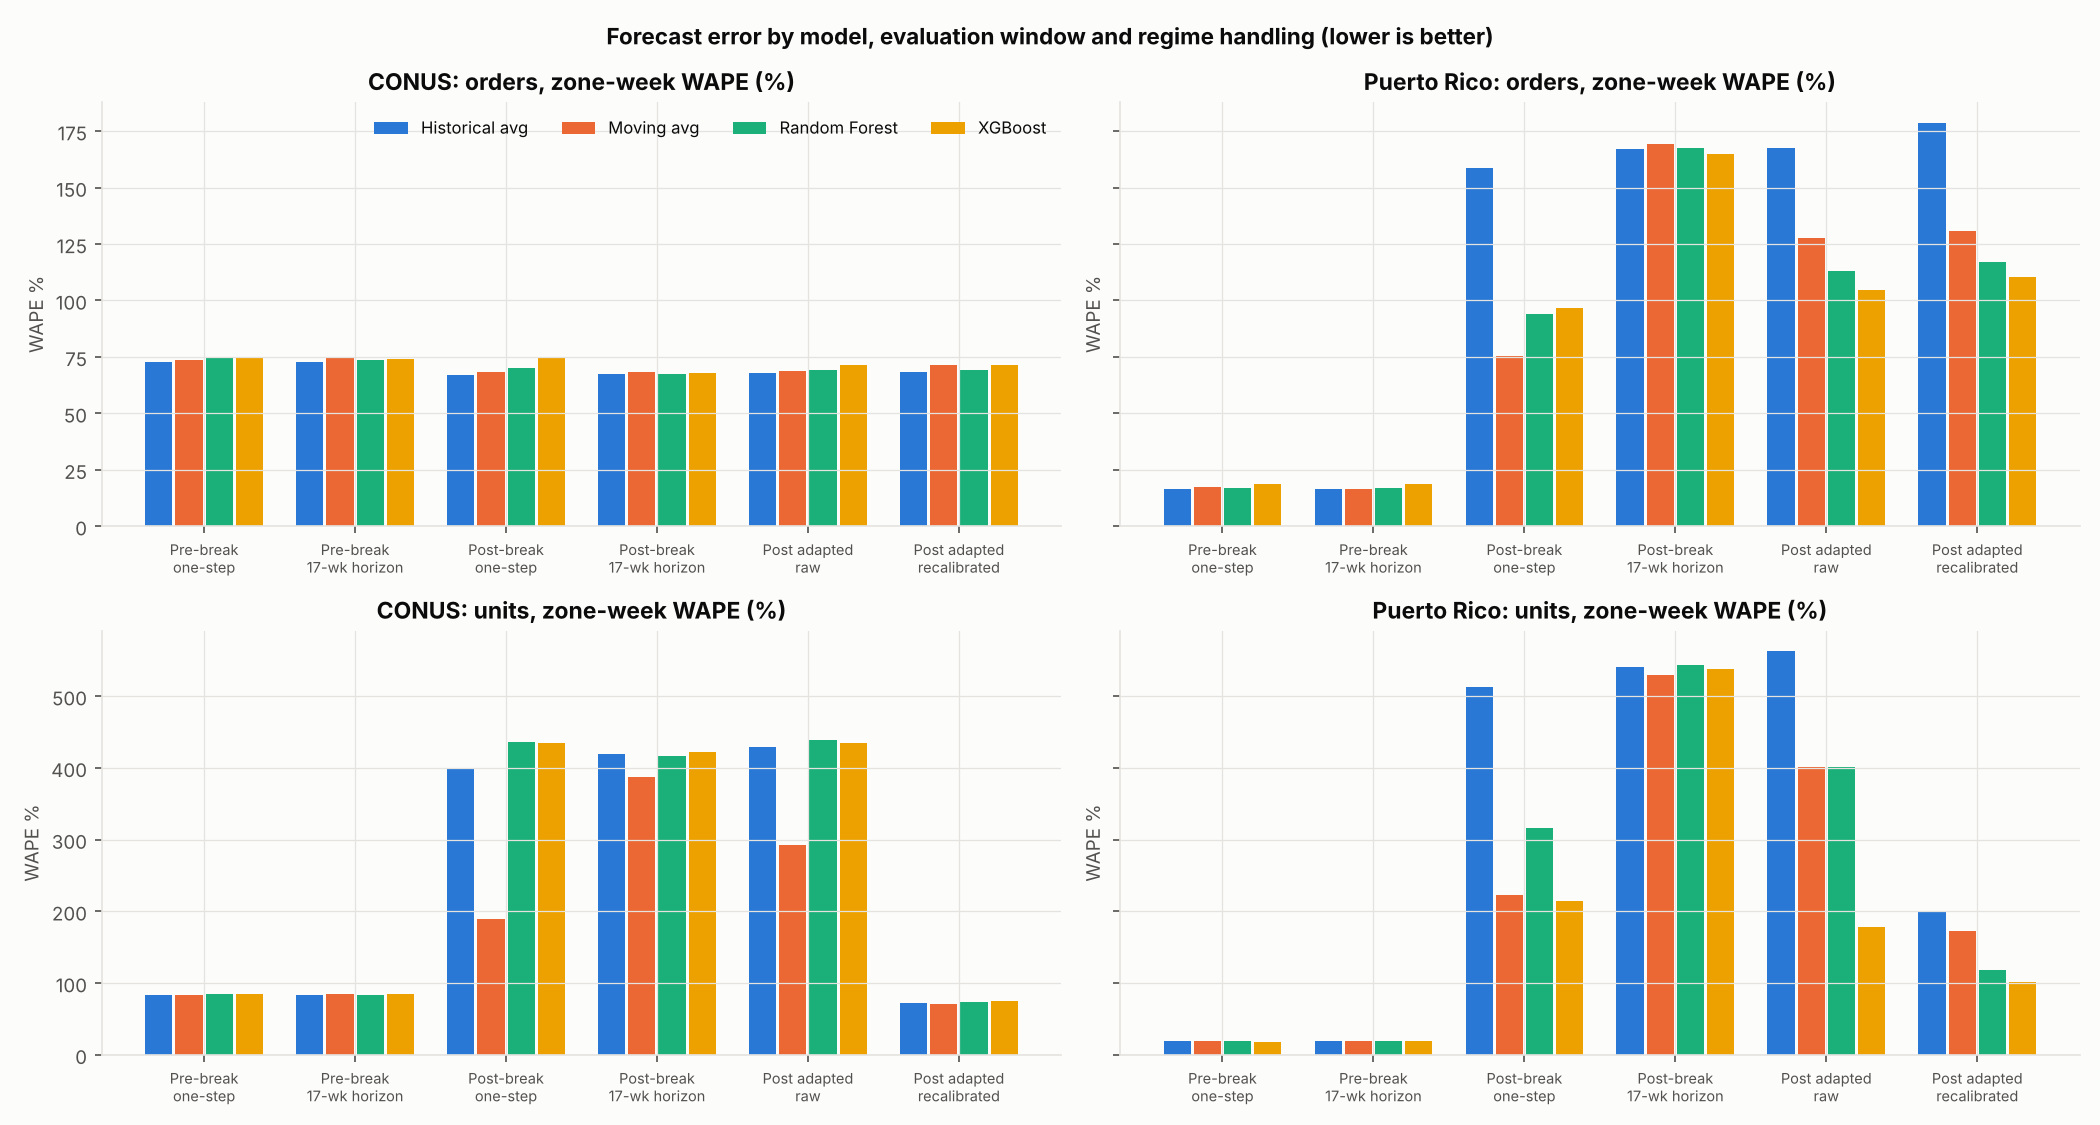

In [6]:
display(Image('reports/figures/phase3_post_break_adaptation.png')); display(Image('reports/figures/phase3_model_wape_comparison_W.png'))

## 3. Zone-demand tiers, granularity, feature importance

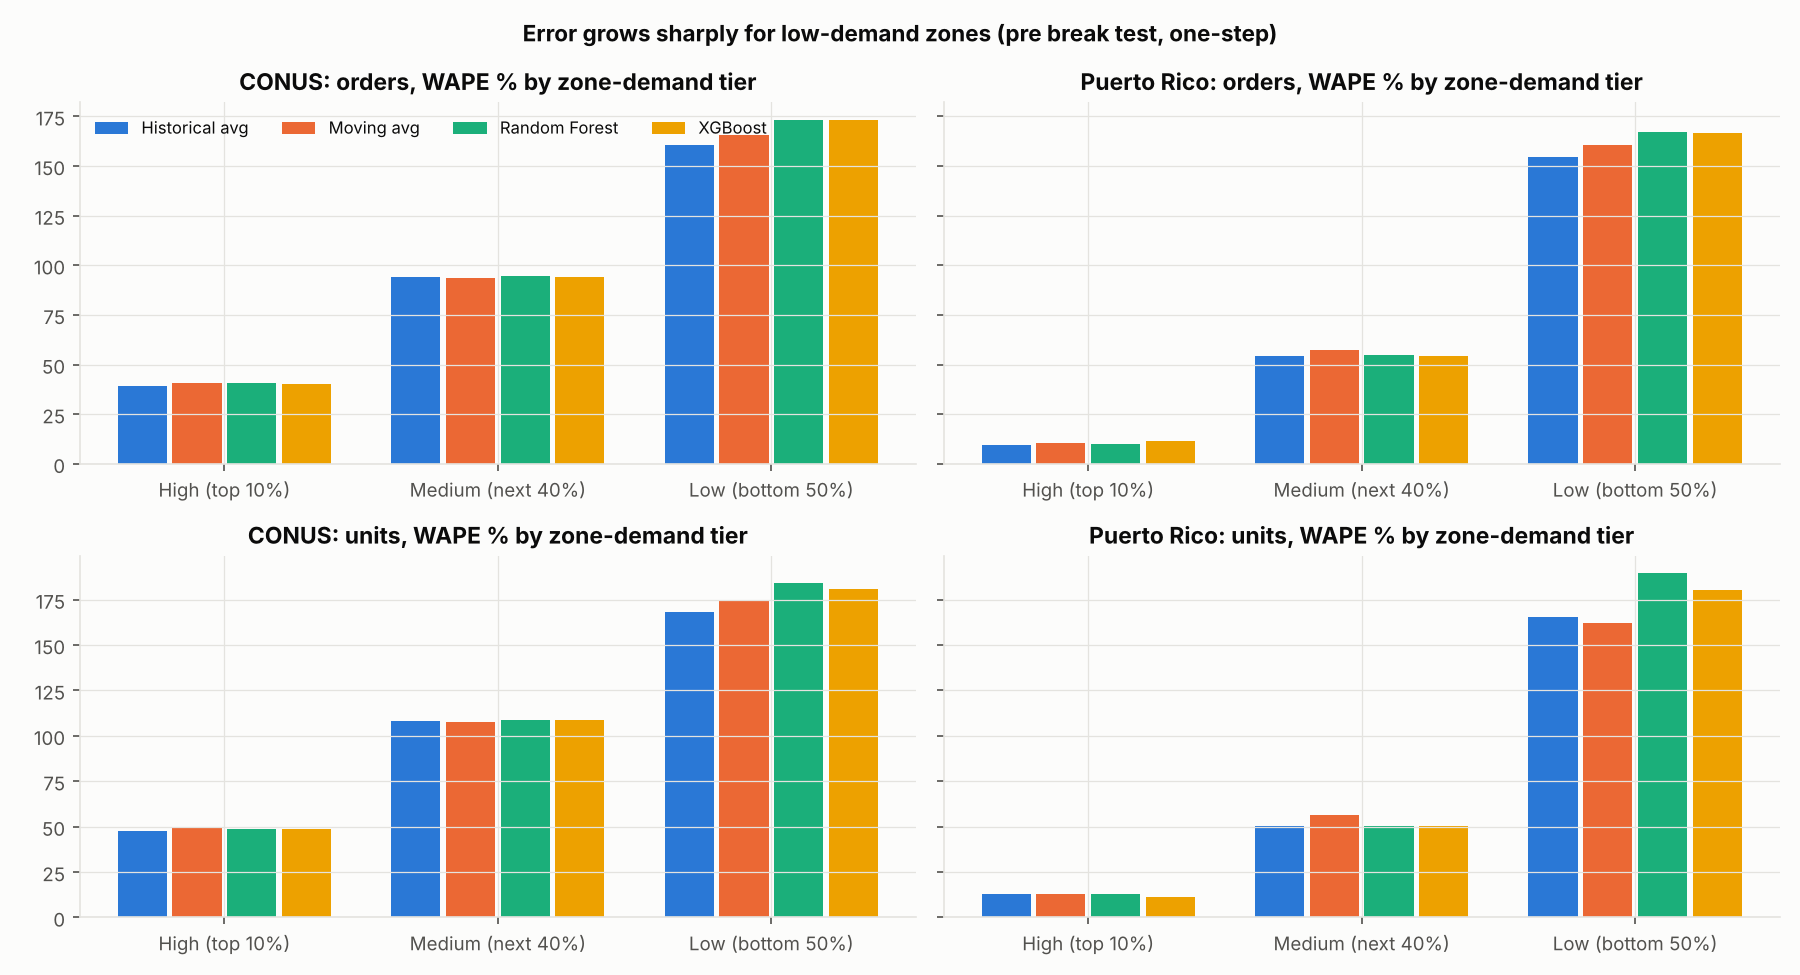

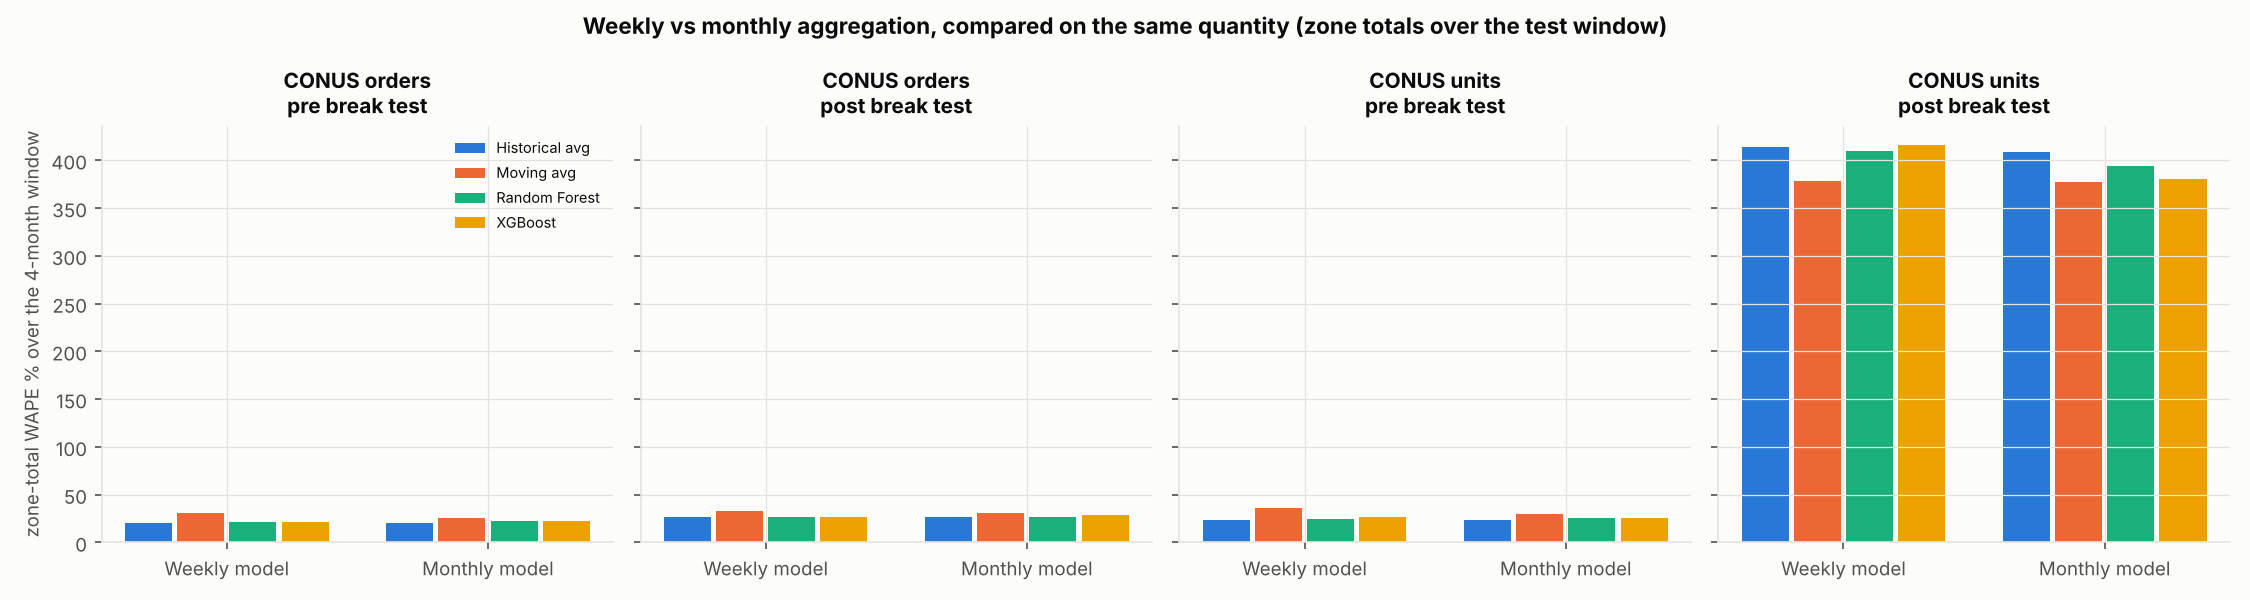

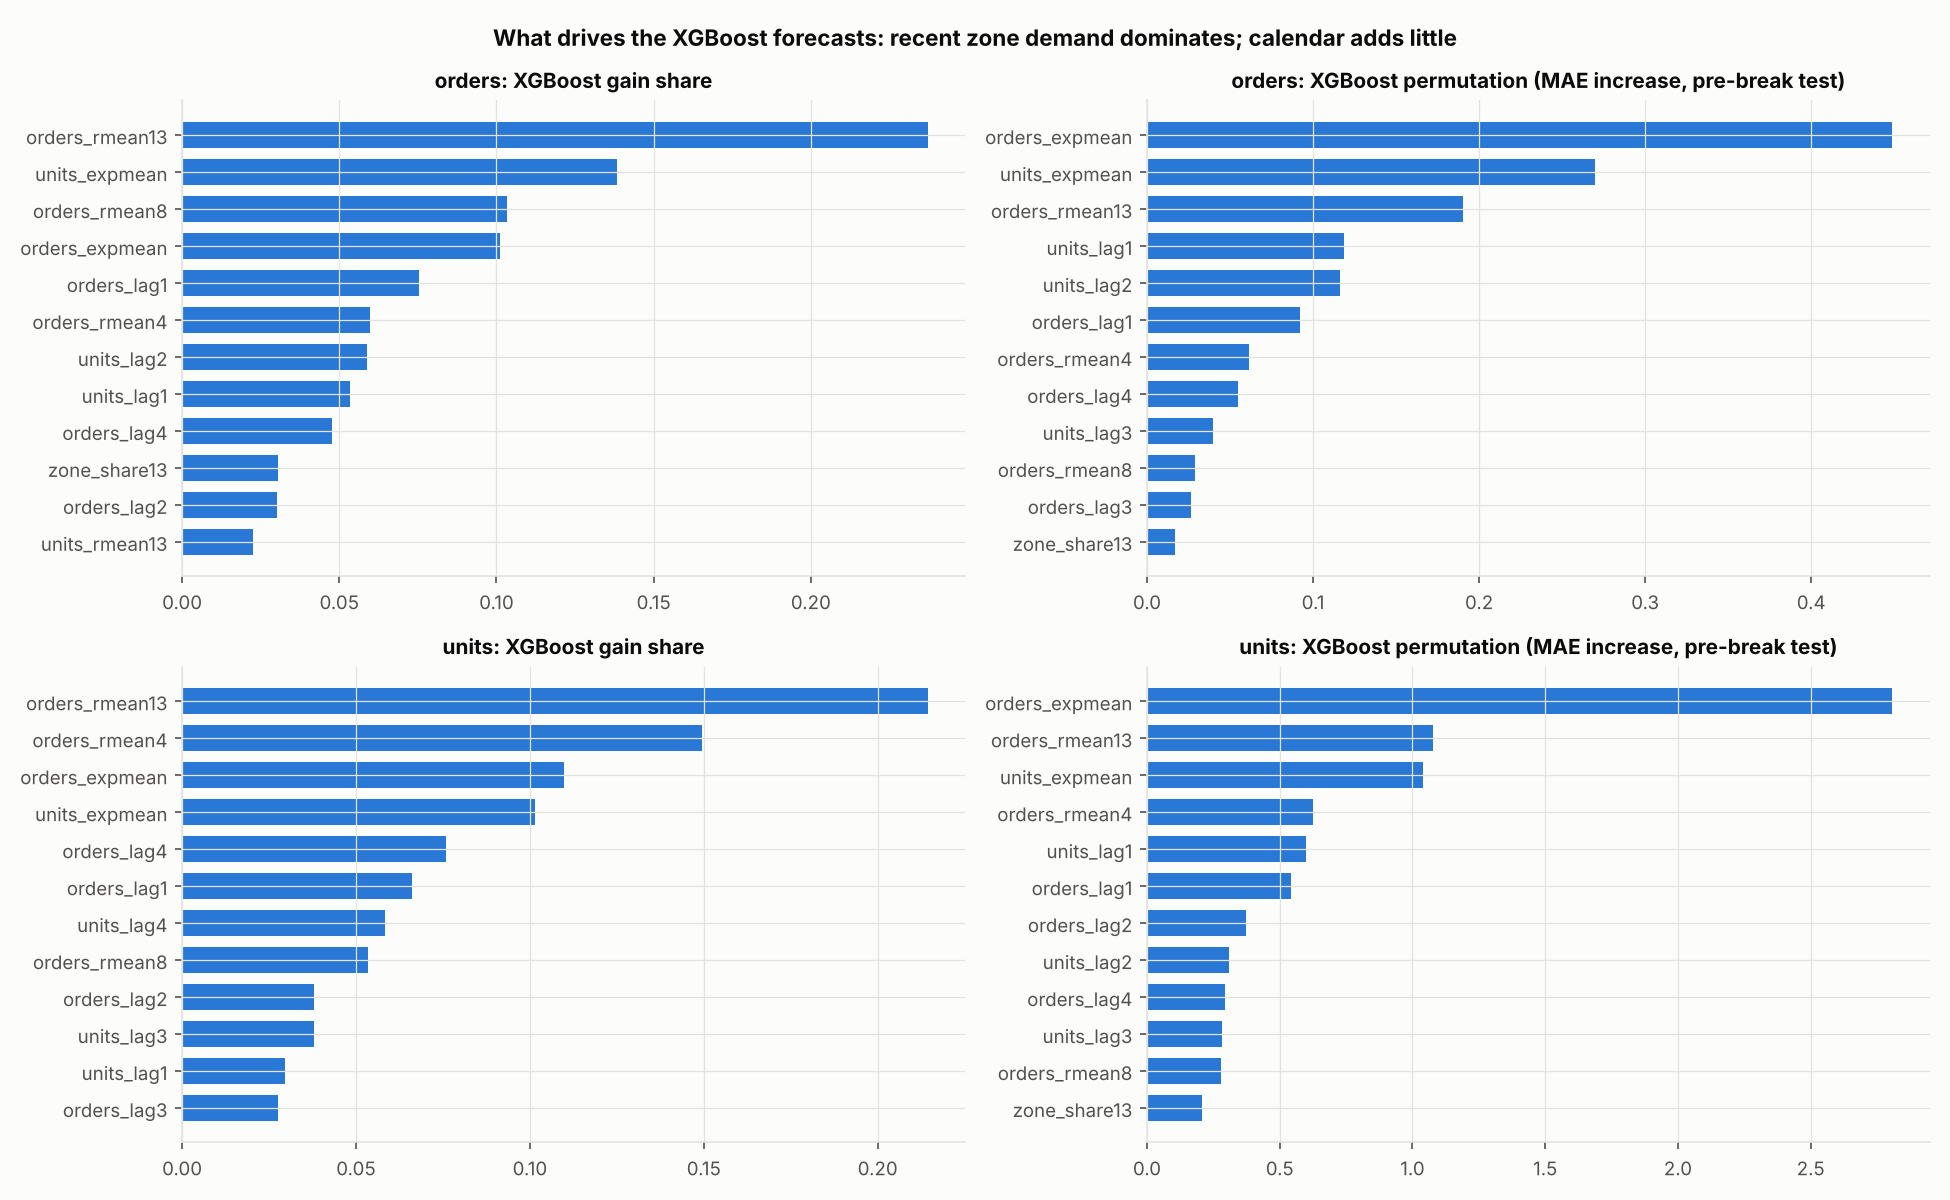

In [7]:
for f in ['phase3_tier_wape_pre_break_test','phase3_weekly_vs_monthly','phase3_feature_importance']:
    display(Image(f'reports/figures/{f}.png'))

## 4. Selected models and the CFLP demand input

,target,network,model,handling,WAPE,MAE,RMSE,bias_pct,selection_level
0,orders,CONUS,share_x_recent_level,regime_reset,0.242074,2.806356,4.258783,0.003663,zone_total
1,orders,Puerto Rico,post_break_average,regime_reset,0.254384,23.210000,54.697235,-0.029702,zone_total
2,units,CONUS,random_forest,recalibrated,0.303613,3.519765,6.202645,0.187591,zone_total
3,units,Puerto Rico,post_break_average,regime_reset,0.462407,42.190000,111.364121,0.203968,zone_total


,forecast_per_period_orders,forecast_per_period_units,historical_avg_per_period_all_orders,historical_avg_per_period_post_break_orders
network,,,,
CONUS,279.5,297.8,233.4,278.5
Puerto Rico,175.5,175.5,148.9,174.2


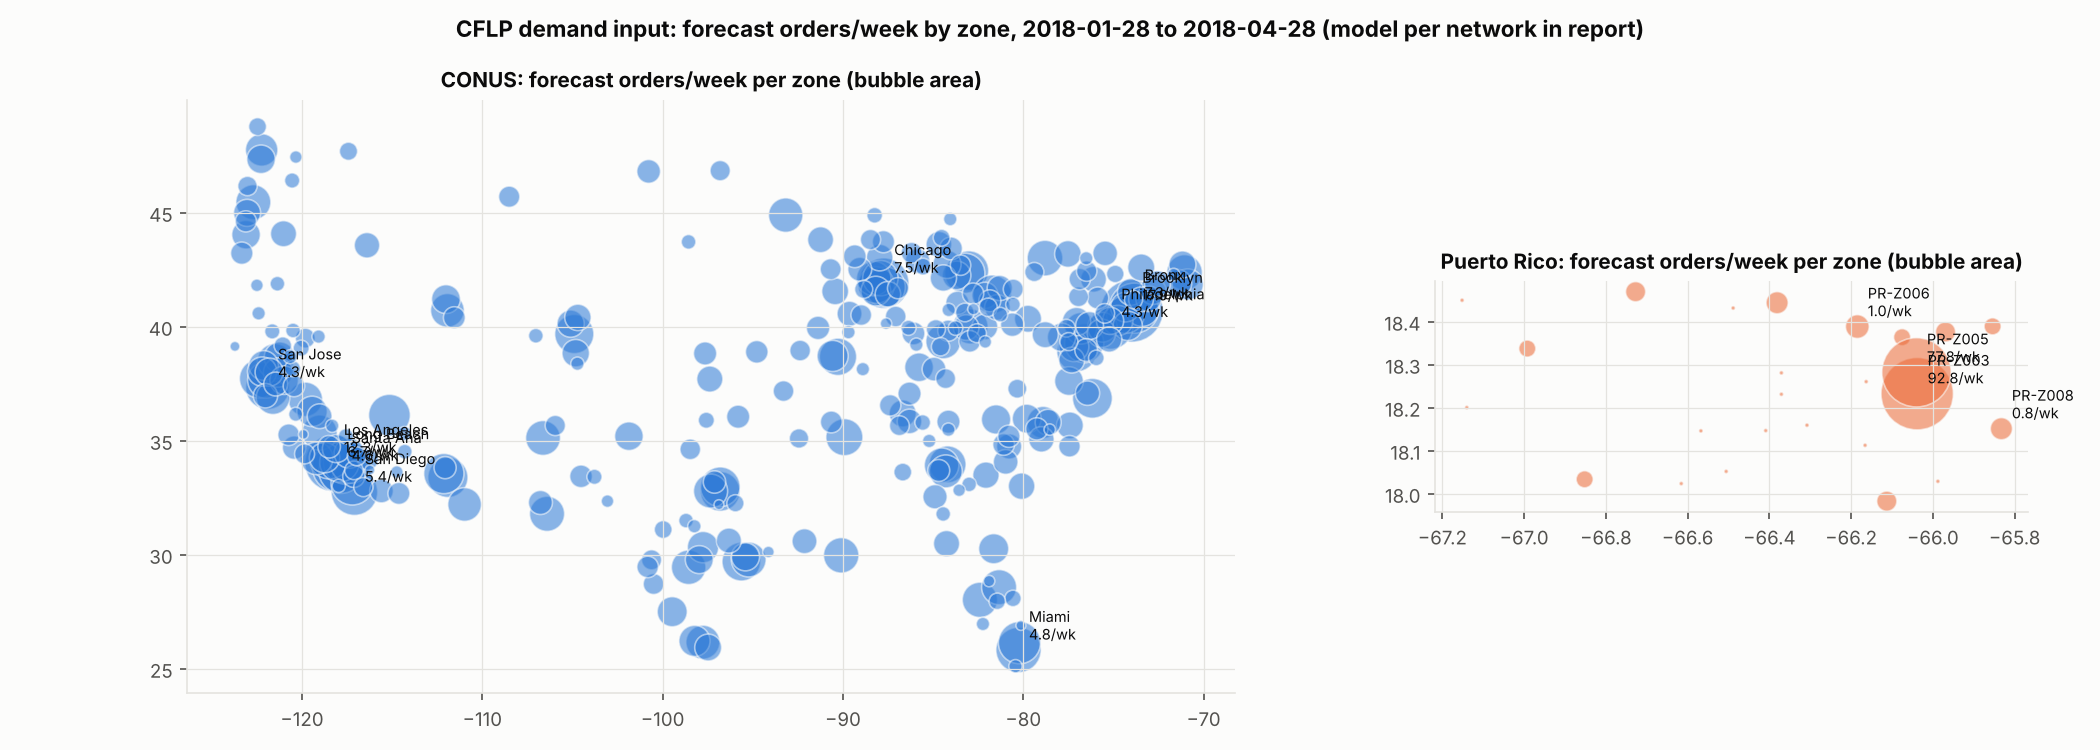

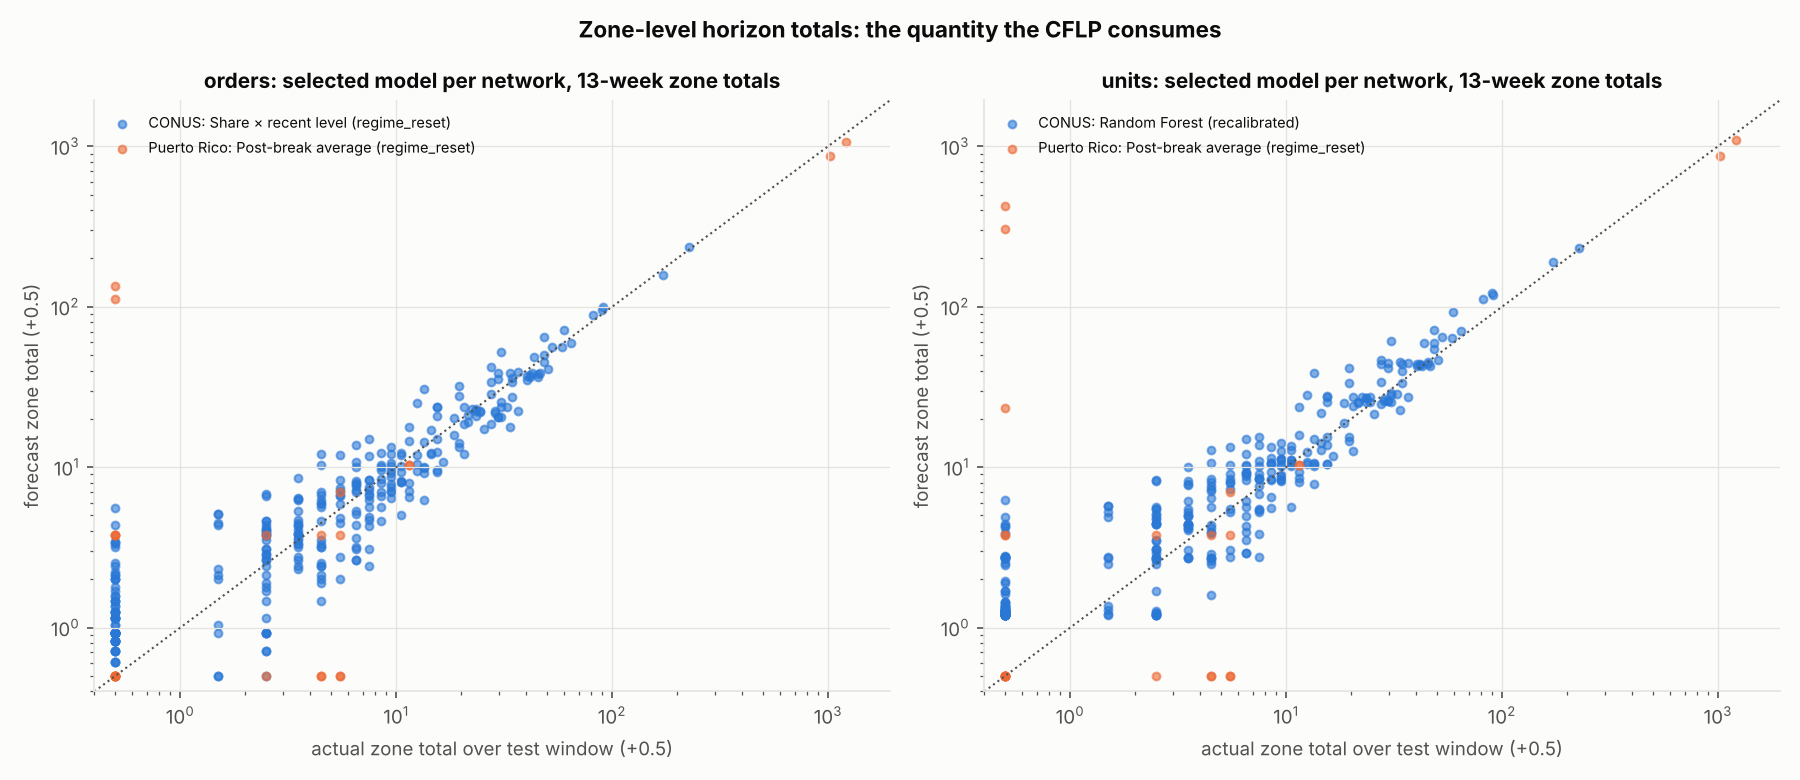

In [8]:
display(sel)
display(cflp.groupby('network')[['forecast_per_period_orders','forecast_per_period_units','historical_avg_per_period_all_orders','historical_avg_per_period_post_break_orders']].sum().round(1))
display(Image('reports/figures/phase3_cflp_demand_forecast_map.png')); display(Image('reports/figures/phase3_zone_total_scatter.png'))

## 5. Reload the saved model and reproduce the forecast

In [9]:
from src import forecasting as fc
bundle = joblib.load(ROOT / 'models/demand_forecasting_model.pkl')
zd = pd.read_csv('data/processed/zone_daily_demand.csv', parse_dates=['date']); zones = pd.read_csv('data/processed/demand_zones.csv')
panel = fc.build_panel(zd, zones, 'W')
H = 13
hz = fc.horizon(bundle['models'], panel, panel.T - 1, H, actual=False)
fac = fc.recalibration_factors(fc.one_step(bundle['models'], fc.long_frame(panel), np.arange(panel.T - 4, panel.T)))
print(bundle['selection'])
for r in bundle['selection'].itertuples():
    if r.model in fc.ALL_MODELS:
        p = hz[(hz.target==r.target)&(hz.network==r.network)&(hz.model==r.model)].groupby('zone_id').predicted.mean()
        if r.handling == 'recalibrated':
            p = p * fac[(fac.network==r.network)&(fac.target==r.target)&(fac.model==r.model)].factor.iat[0]
        ref = cflp.set_index('zone_id').loc[p.index, f'forecast_per_period_{r.target}']
        if r.target == 'units':  # the saved file includes the units >= orders coherence step
            ref = ref - cflp.set_index('zone_id').loc[p.index, 'units_coherence_adjustment']
        print(r.target, r.network, r.model, 'max abs diff vs saved CFLP file:', float(np.abs(p - ref).max()))
    else:
        print(r.target, r.network, r.model, '(regime-reset baseline: computed directly from data; no fitted model needed)')

   target      network                 model      handling      WAPE        MAE        RMSE  bias_pct selection_level
0  orders        CONUS  share_x_recent_level  regime_reset  0.242074   2.806356    4.258783  0.003663      zone_total
1  orders  Puerto Rico    post_break_average  regime_reset  0.254384  23.210000   54.697235 -0.029702      zone_total
2   units        CONUS         random_forest  recalibrated  0.303613   3.519765    6.202645  0.187591      zone_total
3   units  Puerto Rico    post_break_average  regime_reset  0.462407  42.190000  111.364121  0.203968      zone_total
orders CONUS share_x_recent_level (regime-reset baseline: computed directly from data; no fitted model needed)
orders Puerto Rico post_break_average (regime-reset baseline: computed directly from data; no fitted model needed)
units CONUS random_forest max abs diff vs saved CFLP file: 8.881784197001252e-16
units Puerto Rico post_break_average (regime-reset baseline: computed directly from data; no fitted mod